# CA1: AI, Data Science and Software Employment in the USA

**Name:** Numan Liaqat  
**Student number:** 2023461 
**GitHub repository:** https://github.com/sheikhaDaMunda/DataVis_CA1  
**Video link:** PASTE LINK  

This notebook uses the May 2023 Occupational Employment and Wage Statistics data from the U.S. Bureau of Labor Statistics. I look at seven occupations connected to AI, data science and software development, and for each chart I explain the objective, why I picked that chart type, and what I learned from it.

## Loading and preparing the data

The dataset repeats each occupation at many levels (national, state, metro area and industry), so I filter to one level before each chart to avoid counting the same jobs twice. Some wage and employment values are stored as symbols such as * and #, so I convert those columns to numbers first.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("data/all_data_M_2023.xlsx")
df.head()

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


In [2]:
print(df.shape)
print(df.columns.tolist())
print(df["AREA_TYPE"].value_counts())
print(df["O_GROUP"].value_counts())

(413327, 32)
['AREA', 'AREA_TITLE', 'AREA_TYPE', 'PRIM_STATE', 'NAICS', 'NAICS_TITLE', 'I_GROUP', 'OWN_CODE', 'OCC_CODE', 'OCC_TITLE', 'O_GROUP', 'TOT_EMP', 'EMP_PRSE', 'JOBS_1000', 'LOC_QUOTIENT', 'PCT_TOTAL', 'PCT_RPT', 'H_MEAN', 'A_MEAN', 'MEAN_PRSE', 'H_PCT10', 'H_PCT25', 'H_MEDIAN', 'H_PCT75', 'H_PCT90', 'A_PCT10', 'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90', 'ANNUAL', 'HOURLY']
AREA_TYPE
1    177501
4    149591
6     48559
2     36643
3      1033
Name: count, dtype: int64
O_GROUP
detailed    306185
broad        62131
minor        23374
major        20601
total         1036
Name: count, dtype: int64


In [3]:
num_cols = ["TOT_EMP", "A_MEAN", "A_MEDIAN", "A_PCT10", "A_PCT25", "A_PCT75", "A_PCT90"]
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [4]:
jobs = {
    "15-2051": "Data Scientists",
    "15-1252": "Software Developers",
    "15-1221": "Computer & Info Research Scientists",
    "15-1243": "Database Architects",
    "15-2041": "Statisticians",
    "15-1253": "Software QA Analysts & Testers",
    "15-1211": "Computer Systems Analysts",
}
tech = df[df["OCC_CODE"].isin(jobs.keys())].copy()
tech["JOB"] = tech["OCC_CODE"].map(jobs)

In [5]:
national = tech[(tech["AREA_TYPE"] == 1) & (tech["I_GROUP"] == "cross-industry")]
states = tech[tech["AREA_TYPE"] == 2]
industry = tech[(tech["AREA_TYPE"] == 1) & (tech["I_GROUP"] == "sector")]

national[["JOB", "TOT_EMP", "A_MEAN", "A_MEDIAN"]]

,JOB,TOT_EMP,A_MEAN,A_MEDIAN
135,Computer Systems Analysts,498810.0,110800.0,103800.0
138,Computer & Info Research Scientists,35210.0,157160.0,145080.0
145,Database Architects,59920.0,137030.0,134700.0
149,Software Developers,1656880.0,138110.0,132270.0
150,Software QA Analysts & Testers,203040.0,108460.0,101800.0
163,Statisticians,29950.0,109190.0,104110.0
165,Data Scientists,192710.0,119040.0,108020.0


## 1. Bar Chart: Employment by Occupation

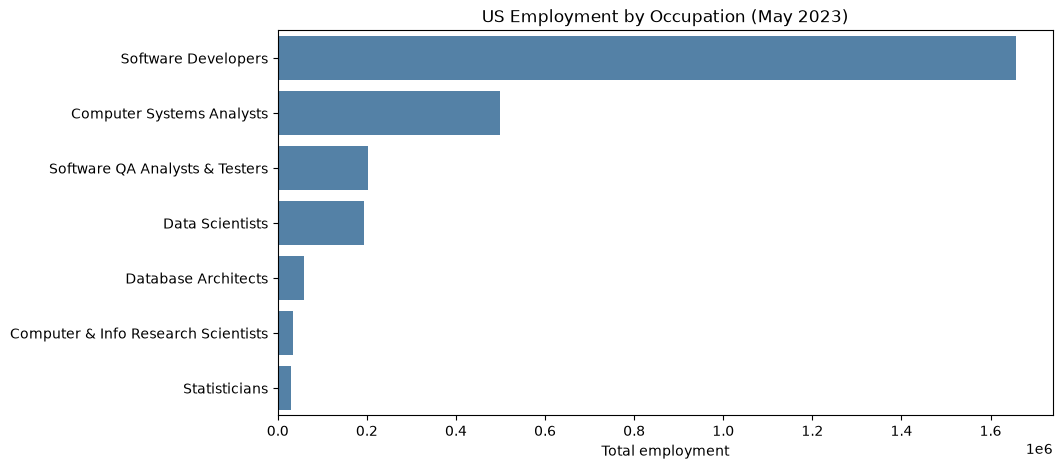

In [6]:
d = national.sort_values("TOT_EMP", ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(x="TOT_EMP", y="JOB", data=d, color="steelblue")
plt.title("US Employment by Occupation (May 2023)")
plt.xlabel("Total employment")
plt.ylabel("")
plt.show()

- **Objective:** To compare how many people work in each of the seven occupations across the whole USA.
- **Why this plot:** Each occupation is a category with one number attached, and a bar chart is the simplest way to compare those. I made it horizontal because the job titles are long and would overlap on a vertical axis. I also sorted the bars so the ranking is obvious.
- **Learning:** Software Developers are far ahead of everything else with about 1.66 million jobs, which is more than 8 times the number of Data Scientists (192,710). The roles closest to AI research are very small in comparison: Computer and Information Research Scientists have only 35,210 jobs and Statisticians 29,950. So most employment in this area is in building software, not in research.

## 2. Pie Chart: Share of Employment

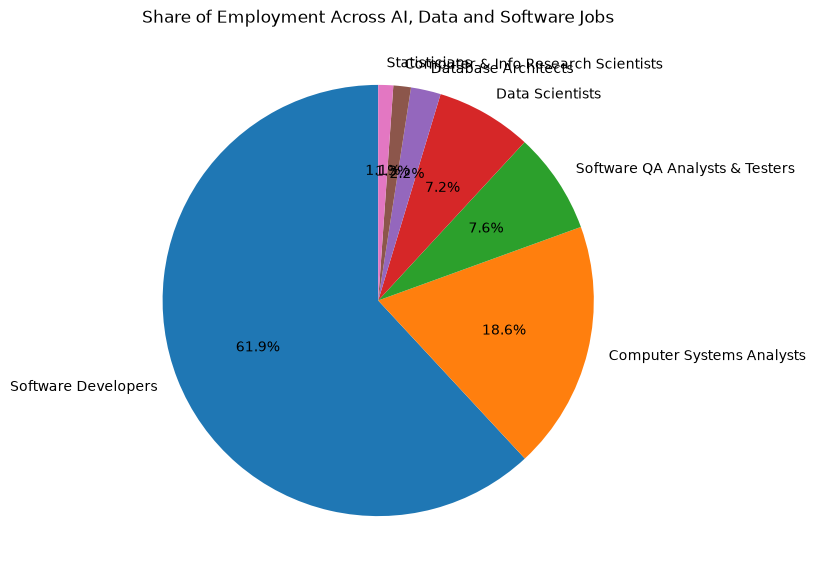

In [7]:
plt.figure(figsize=(7, 7))
plt.pie(d["TOT_EMP"], labels=d["JOB"], autopct="%1.1f%%", startangle=90)
plt.title("Share of Employment Across AI, Data and Software Jobs")
plt.show()

- **Objective:** To see what share of the total each occupation makes up, instead of the raw counts.
- **Why this plot:** A pie chart works for part-of-a-whole data when there are only a few categories. Here there are seven, and one clearly dominates, which a pie shows well.
- **Learning:** Software Developers make up 61.9% of the seven occupations combined. Computer Systems Analysts are second at 18.6%, then QA Analysts and Testers at 7.6% and Data Scientists at 7.2%. Database Architects, Research Scientists and Statisticians together are under 5%. A weakness of the pie chart is that these small slices are hard to tell apart, which is why I used the bar chart as well.

## 3. Horizontal Bar Chart: Top 10 States for Data Scientists

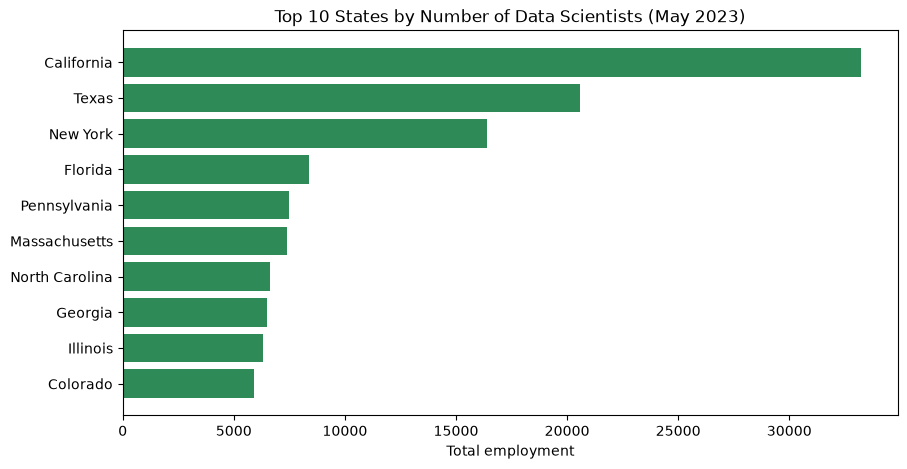

In [8]:
ds = states[states["OCC_CODE"] == "15-2051"].sort_values("TOT_EMP", ascending=False).head(10)
plt.figure(figsize=(10, 5))
plt.barh(ds["AREA_TITLE"], ds["TOT_EMP"], color="seagreen")
plt.gca().invert_yaxis()
plt.title("Top 10 States by Number of Data Scientists (May 2023)")
plt.xlabel("Total employment")
plt.show()

- **Objective:** To find out where in the USA data scientists are concentrated.
- **Why this plot:** This is a ranking, and a horizontal bar chart reads naturally from top to bottom with the state names easy to read. I limited it to the top 10 because 50 bars would be too cluttered.
- **Learning:** California has the most data scientists with 33,220, followed by Texas (20,560) and New York (16,390). These three states alone hold about 36% of all data scientists in the country. Data science jobs are clearly clustered in states with large tech and finance sectors and are not spread evenly.

## 4. Boxplot: Wage Distribution Across States

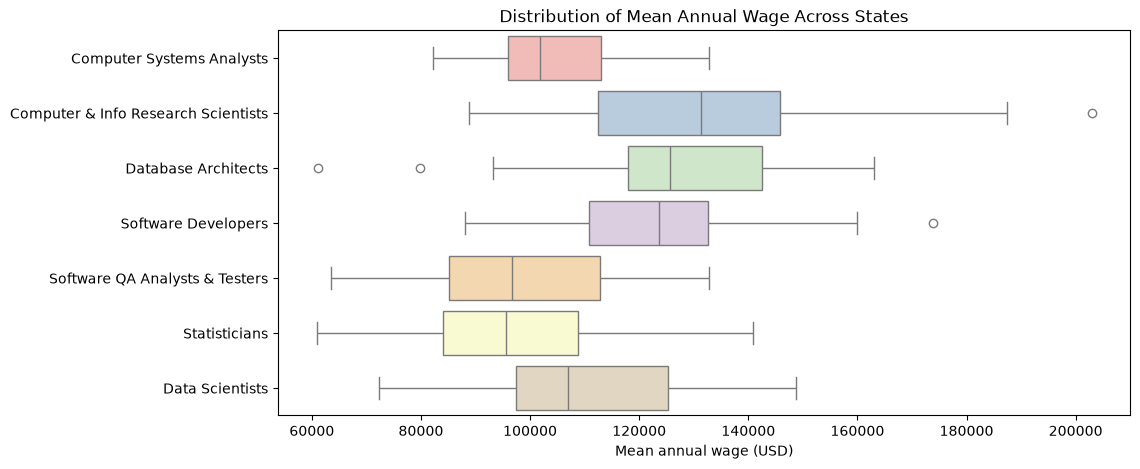

In [9]:
plt.figure(figsize=(11, 5))
sns.boxplot(x="A_MEAN", y="JOB", hue="JOB", data=states, palette="Pastel1", legend=False)
plt.title("Distribution of Mean Annual Wage Across States")
plt.xlabel("Mean annual wage (USD)")
plt.ylabel("")
plt.show()

- **Objective:** To compare how the average wage for each occupation varies from state to state.
- **Why this plot:** I wanted to see more than a single average. A boxplot shows the median, the spread and any outliers together, so I can compare both the level and the consistency of pay for each job.
- **Learning:** Computer and Information Research Scientists have the highest median state wage at around $131,000 and also the widest spread, from about $89,000 to $203,000 depending on the state. Software QA Analysts and Statisticians are the lowest, with medians near $96,000. This suggests the roles closest to AI research pay the most, but what you earn depends a lot on where you work.

## 5. Scatterplot: Employment vs Mean Wage by State

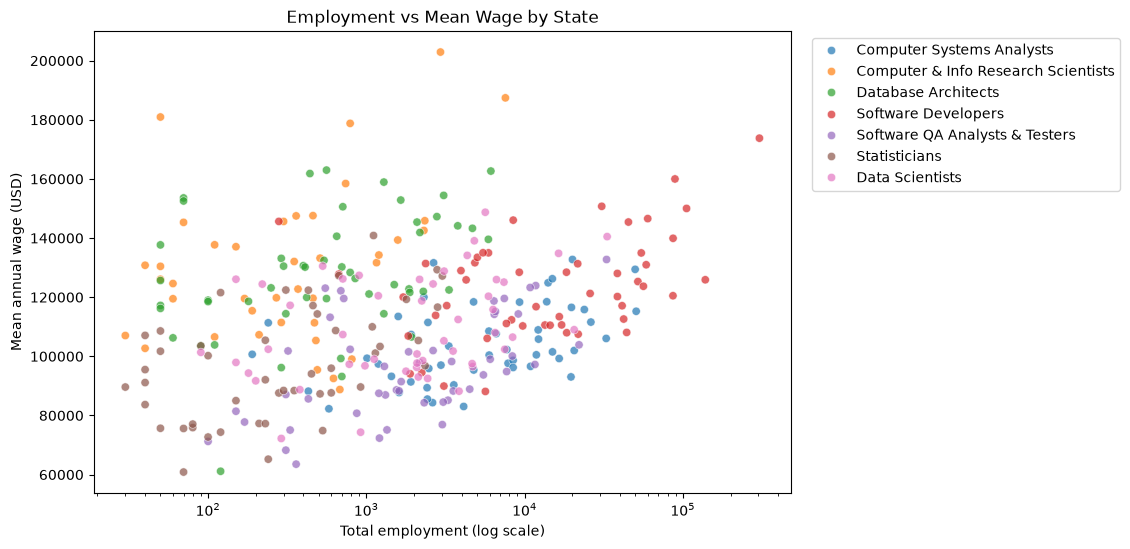

In [10]:
plt.figure(figsize=(9, 6))
sns.scatterplot(x="TOT_EMP", y="A_MEAN", hue="JOB", data=states, alpha=0.7)
plt.xscale("log")
plt.title("Employment vs Mean Wage by State")
plt.xlabel("Total employment (log scale)")
plt.ylabel("Mean annual wage (USD)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

- **Objective:** To check whether states with more jobs in these occupations also pay higher wages.
- **Why this plot:** Both variables are numeric, and a scatterplot is the standard way to look for a relationship between two numbers. I used a log scale on the employment axis because a few large states would otherwise squash all the other points together. Colour shows the occupation.
- **Learning:** There is a positive relationship but it is weak (correlation of about 0.26). States with more tech jobs tend to pay a bit more, but the colours show that the type of job matters more than the size of the state. Research Scientists sit near the top of the chart even in states with few of them.

## 6. Heatmap: Employment by Industry and Occupation

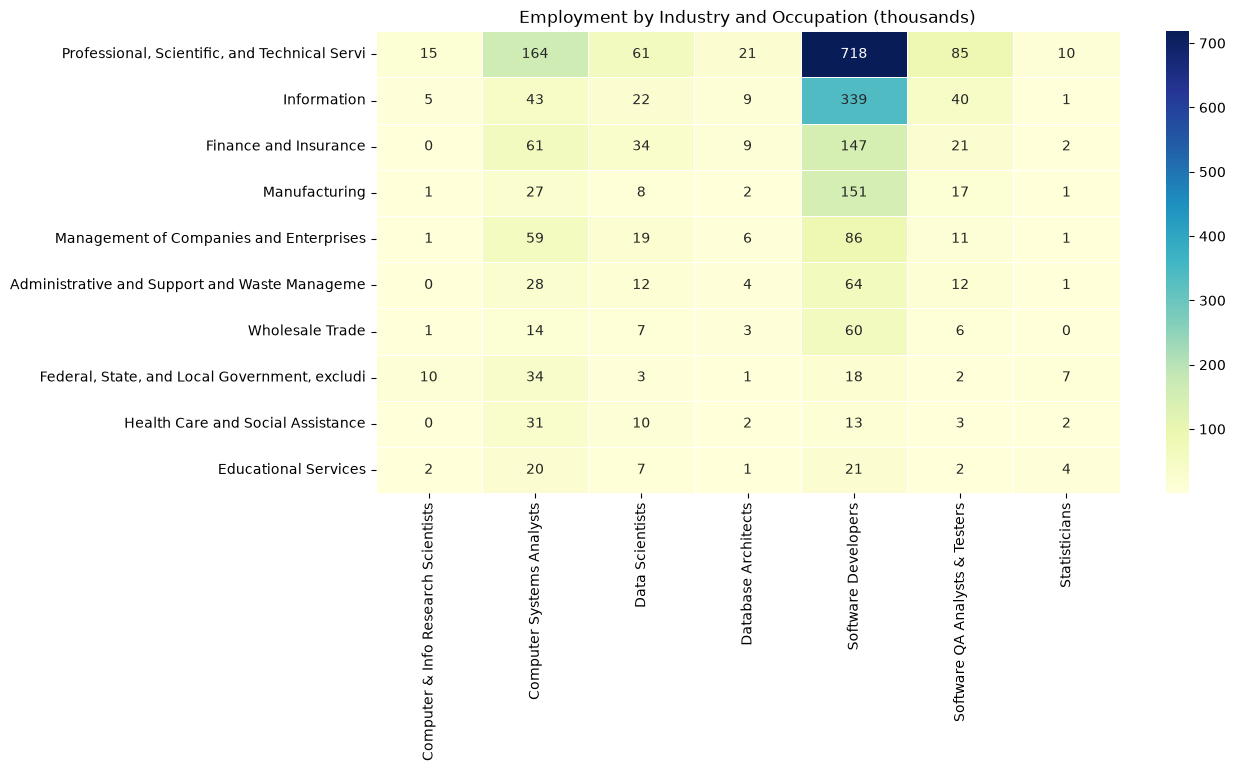

In [11]:
pivot = industry.pivot_table(index="NAICS_TITLE", columns="JOB", values="TOT_EMP", aggfunc="sum")
pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=False).head(10).index]
pivot.index = pivot.index.str.slice(0, 45)

plt.figure(figsize=(12, 6))
sns.heatmap(pivot / 1000, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=0.5)
plt.title("Employment by Industry and Occupation (thousands)")
plt.xlabel("")
plt.ylabel("")
plt.show()

- **Objective:** To see which industries employ each of these occupations.
- **Why this plot:** This compares two categories (industry and occupation) with one number in each cell. A heatmap handles that well because the colour makes the biggest values stand out straight away, which a table of 70 numbers would not.
- **Learning:** Professional, Scientific and Technical Services is the biggest employer by a long way, with about 718,500 software developers, followed by the Information sector with about 339,000. An interesting result is government: it employs few developers, but it is the second largest employer of Research Scientists (9,970) and Statisticians (7,200). So AI research work is not only in tech companies.

# Challenge: AI Employment Trends Over Time

For this part I downloaded the National datasets for the other available years from https://www.bls.gov/oes/tables.htm and combined them with the May 2023 data, keeping the same seven occupations. I start from 2021 because that is the first year where the current occupation codes are used, for example Data Scientists (15-2051) did not exist as a separate occupation before then, so earlier years cannot be compared fairly.

In [12]:
import glob, re

frames = []
for path in sorted(glob.glob("data/national_M*_dl.xlsx")):
    year = int(re.search(r"(\d{4})", path).group(1))
    y = pd.read_excel(path)
    y.columns = y.columns.str.upper()
    y = y[y["OCC_CODE"].isin(jobs.keys())].copy()
    y["YEAR"] = year
    frames.append(y[["YEAR", "OCC_CODE", "TOT_EMP", "A_MEAN"]])
    print("Loaded", path)

y23 = national[["OCC_CODE", "TOT_EMP", "A_MEAN"]].copy()
y23["YEAR"] = 2023
frames.append(y23)

trend = pd.concat(frames, ignore_index=True)
trend = trend.drop_duplicates(subset=["YEAR", "OCC_CODE"])
trend["TOT_EMP"] = pd.to_numeric(trend["TOT_EMP"], errors="coerce")
trend["A_MEAN"] = pd.to_numeric(trend["A_MEAN"], errors="coerce")
trend["JOB"] = trend["OCC_CODE"].map(jobs)
trend = trend.sort_values(["JOB", "YEAR"])

emp = trend.pivot(index="JOB", columns="YEAR", values="TOT_EMP")
wage = trend.pivot(index="JOB", columns="YEAR", values="A_MEAN")
print(emp.to_string())
print(wage.to_string())

Loaded data/national_M2021_dl.xlsx
Loaded data/national_M2022_dl.xlsx
Loaded data/national_M2023_dl.xlsx
Loaded data/national_M2024_dl.xlsx
Loaded data/national_M2025_dl.xlsx
YEAR                                      2021       2022       2023       2024       2025
JOB                                                                                       
Computer & Info Research Scientists    30840.0    33780.0    35210.0    38480.0    37200.0
Computer Systems Analysts             505150.0   505210.0   498810.0   497800.0   519530.0
Data Scientists                       105980.0   159630.0   192710.0   233440.0   262440.0
Database Architects                    50440.0    62470.0    59920.0    64770.0    67140.0
Software Developers                  1364180.0  1534790.0  1656880.0  1654440.0  1687890.0
Software QA Analysts & Testers        190120.0   196420.0   203040.0   199800.0   186740.0
Statisticians                          31370.0    30780.0    29950.0    29800.0    29030.0
YEAR  

## 7. Line Chart: Employment Over Time

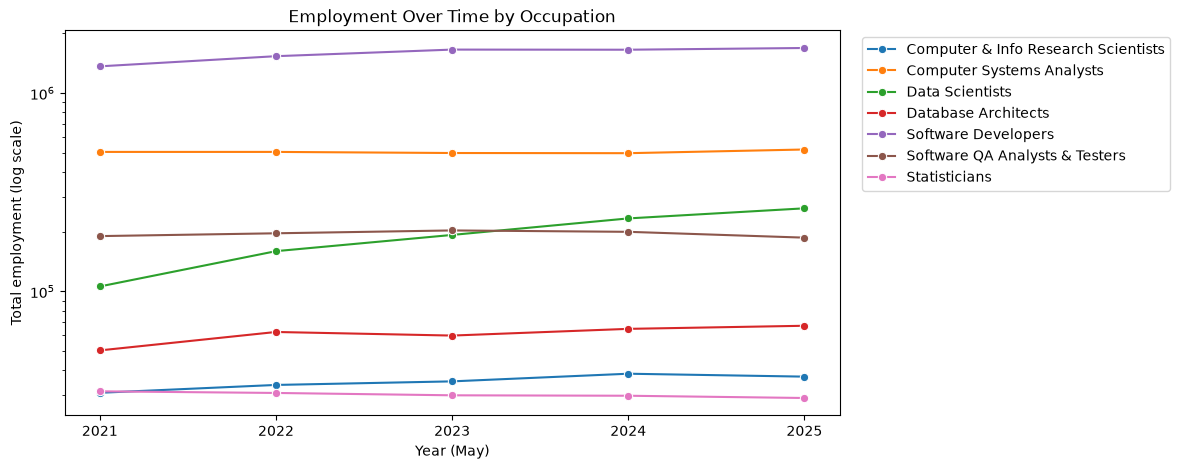

In [13]:
plt.figure(figsize=(10, 5))
sns.lineplot(x="YEAR", y="TOT_EMP", hue="JOB", data=trend, marker="o")
plt.yscale("log")
plt.xticks(sorted(trend["YEAR"].unique()))
plt.title("Employment Over Time by Occupation")
plt.xlabel("Year (May)")
plt.ylabel("Total employment (log scale)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

- **Objective:** To see how employment in each occupation has changed from year to year.
- **Why this plot:** Time is continuous, and a line chart is the natural choice for showing change over time because the slope of each line shows the direction and speed of change. I used a log scale so the small occupations are not flattened by Software Developers.
- **Learning:** Data Scientists grew the fastest, from about 106,000 jobs in 2021 to about 262,000 in 2025. Software Developers went up until 2023 (1.36 million to 1.66 million) but after that the line is nearly flat. Statisticians dropped a little every year. So most of the growth is in data science, and software jobs have slowed down since 2023.

## 8. Bar Chart: Percentage Change in Employment

JOB
Statisticians                           -7.5
Software QA Analysts & Testers          -1.8
Computer Systems Analysts                2.8
Computer & Info Research Scientists     20.6
Software Developers                     23.7
Database Architects                     33.1
Data Scientists                        147.6


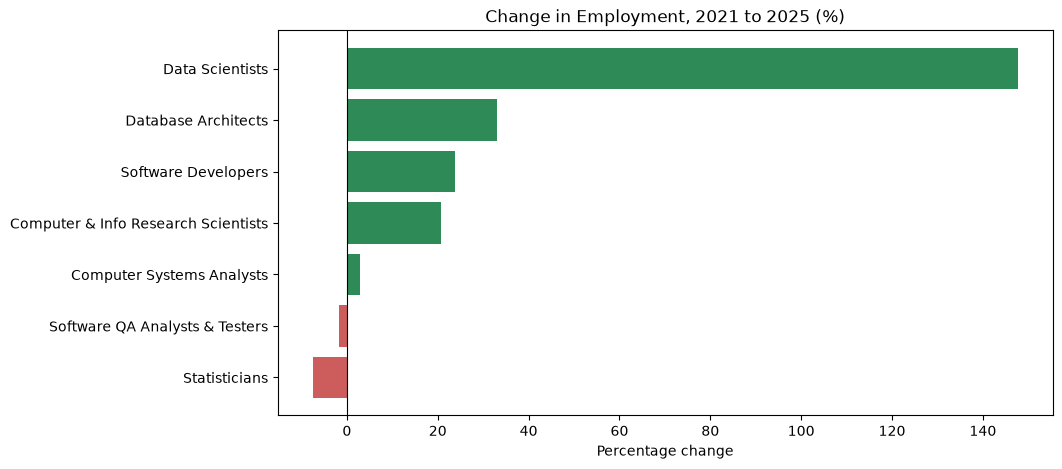

In [14]:
first_year = trend["YEAR"].min()
last_year = trend["YEAR"].max()
growth = ((emp[last_year] - emp[first_year]) / emp[first_year] * 100).sort_values()
print(growth.round(1).to_string())

colors = ["indianred" if g < 0 else "seagreen" for g in growth]
plt.figure(figsize=(10, 5))
plt.barh(growth.index, growth.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title(f"Change in Employment, {first_year} to {last_year} (%)")
plt.xlabel("Percentage change")
plt.show()

- **Objective:** To compare which occupations grew or shrank the most over the whole period.
- **Why this plot:** The line chart shows the path, but it is hard to compare growth rates between a job with 30,000 people and one with 1.6 million. Turning the change into a percentage puts every occupation on the same scale, and green and red bars show growth and decline at a glance.
- **Learning:** Data Scientist jobs grew by 147.6% from 2021 to 2025, which is way more than any other job. Next were Database Architects (33.1%) and Software Developers (23.7%). Two jobs actually got smaller: Statisticians (-7.5%) and Software QA Testers (-1.8%). This shows demand is moving towards jobs that work with data and AI, and away from older roles like statistics and testing.

## 9. Line Chart: Mean Wage Over Time

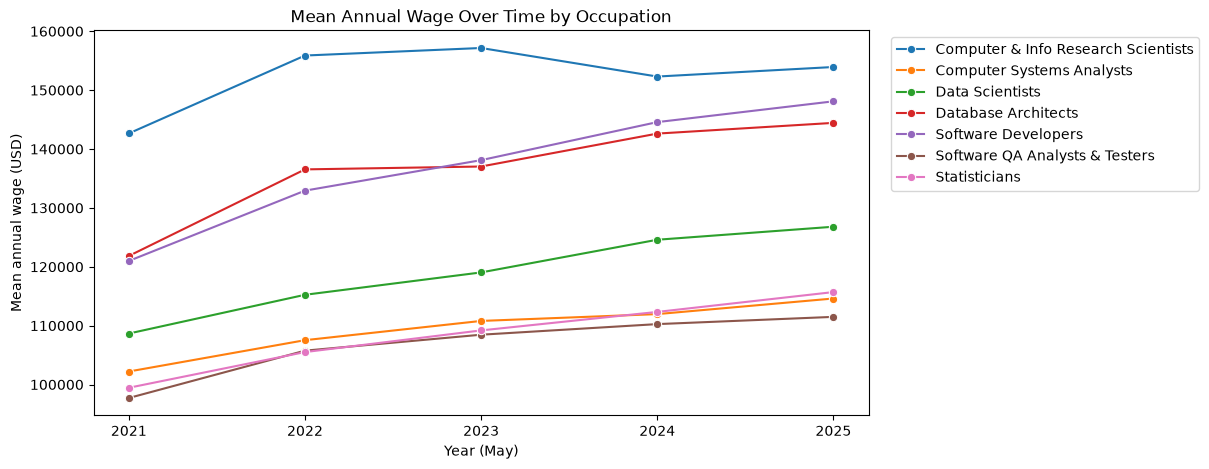

In [15]:
plt.figure(figsize=(10, 5))
sns.lineplot(x="YEAR", y="A_MEAN", hue="JOB", data=trend, marker="o")
plt.xticks(sorted(trend["YEAR"].unique()))
plt.title("Mean Annual Wage Over Time by Occupation")
plt.xlabel("Year (May)")
plt.ylabel("Mean annual wage (USD)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

- **Objective:** To see whether pay in these occupations has kept rising alongside employment.
- **Why this plot:** Again this is a change over time, so a line chart fits, with one line per occupation for direct comparison.
- **Learning:** Wages went up for all seven jobs. Software Developers had the biggest rise, from $120,990 to $148,100. Data Scientists went from $108,660 to $126,800. Research Scientists are still paid the most, but their wage peaked in 2023 ($157,160) and has dropped a bit since. These numbers are not adjusted for inflation, so the real rise is smaller.

## Overall findings

The main thing I found is that data science is growing much faster than the other jobs. Software development is still the biggest by far, but it has stopped growing much since 2023. AI research jobs are a small group but they pay the most.

One limitation is that BLS says this data is not really made for comparing years, because the survey method changes over time. So I am treating these as general trends and not exact changes.

## References

U.S. Bureau of Labor Statistics (2025) *Occupational Employment and Wage Statistics: OEWS Tables*. Available at: https://www.bls.gov/oes/tables.htm (Accessed: 12 November 2026).